# Retail Sales Forecasting with LSTM

## 1. Initial Data Exploration

The goal of this project is to analyse historical retail sales data and prepare for forecasting future sales using an LSTM neural network.

We will begin by loading the training dataset and examining its structure before making any changes to the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


class DataLoader:
    """Load datasets used in the retail sales forecasting project."""

    def __init__(self, data_dir="../datasets"):
        self.data_dir = data_dir

    def load_csv(self, filename):
        """Load a CSV file and return it as a DataFrame."""
        file_path = f"{self.data_dir}/{filename}"
        data = pd.read_csv(file_path)

        print(f"Loaded {filename} successfully.")
        return data


# Create a DataLoader object
loader = DataLoader()

# Load the historical sales data
train = loader.load_csv("train.csv")

# Display the first five rows
train.head()

Loaded train.csv successfully.


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [2]:
class DataAnalyzer:
    """Inspect, summarise, and visualise retail sales data."""

    def __init__(self, data):
        self.data = data

    def show_shape(self):
        """Display the number of rows and columns."""
        rows, columns = self.data.shape

        print(f"Number of rows: {rows:,}")
        print(f"Number of columns: {columns}")

    def show_columns(self):
        """Display the dataset column names."""
        print("Dataset columns:")

        for column in self.data.columns:
            print(f"- {column}")

    def show_data_types(self):
        """Display the data type of each column."""
        print("Data types:")
        print(self.data.dtypes)

    def show_missing_values(self):
        """Display missing-value counts for each column."""
        print("Missing values:")
        print(self.data.isnull().sum())

    def show_data_coverage(self):
        """Summarise the date range, stores, and product families."""
        dates = pd.to_datetime(self.data["date"])

        print(f"First date: {dates.min().date()}")
        print(f"Last date: {dates.max().date()}")
        print(f"Unique dates: {dates.nunique():,}")
        print(f"Unique stores: {self.data['store_nbr'].nunique():,}")
        print(f"Product families: {self.data['family'].nunique():,}")

    def show_sales_statistics(self):
        """Display summary statistics for sales."""
        sales = self.data["sales"]

        print("Sales Summary Statistics")
        print("-" * 30)
        print(f"Total sales: {sales.sum():,.2f}")
        print(f"Average sales: {sales.mean():,.2f}")
        print(f"Median sales: {sales.median():,.2f}")
        print(f"Minimum sales: {sales.min():,.2f}")
        print(f"Maximum sales: {sales.max():,.2f}")
        print(f"Standard deviation: {sales.std():,.2f}")

    def plot_sales_distribution(self):
        """Plot the distribution of individual sales observations."""
        plt.figure(figsize=(10, 5))

        plt.hist(
            self.data["sales"],
            bins=50,
            edgecolor="black"
        )

        plt.title("Distribution of Retail Sales")
        plt.xlabel("Sales")
        plt.ylabel("Frequency")
        plt.tight_layout()

        plt.savefig("../outputs/figures/01_sales_distribution.png")
        plt.show()

    def plot_daily_sales(self):
        """Plot total sales aggregated by date."""
        data = self.data.copy()
        data["date"] = pd.to_datetime(data["date"])

        daily_sales = (
            data.groupby("date")["sales"]
            .sum()
            .sort_index()
        )

        plt.figure(figsize=(14, 5))
        plt.plot(daily_sales.index, daily_sales.values)

        plt.title("Total Daily Retail Sales")
        plt.xlabel("Date")
        plt.ylabel("Total Sales")
        plt.tight_layout()

        plt.savefig("../outputs/figures/02_daily_sales_trend.png")
        plt.show()

    def plot_weekly_sales(self):
        """Compare average total sales across weekdays."""
        data = self.data.copy()
        data["date"] = pd.to_datetime(data["date"])

        daily_sales = (
            data.groupby("date")["sales"]
            .sum()
            .sort_index()
        )

        average_sales = daily_sales.groupby(
            daily_sales.index.dayofweek
        ).mean()

        day_names = [
            "Monday", "Tuesday", "Wednesday",
            "Thursday", "Friday", "Saturday", "Sunday"
        ]

        average_sales.index = [
            day_names[day] for day in average_sales.index
        ]

        average_sales = average_sales.reindex(day_names)

        plt.figure(figsize=(10, 5))
        plt.bar(
            average_sales.index,
            average_sales.values,
            edgecolor="black"
        )

        plt.title("Average Daily Sales by Day of the Week")
        plt.xlabel("Day of the Week")
        plt.ylabel("Average Total Daily Sales")
        plt.xticks(rotation=30)
        plt.tight_layout()

        plt.savefig("../outputs/figures/03_weekly_sales_patterns.png")
        plt.show()

    def plot_top_stores(self, top_n=10):
        """Plot the stores with the highest cumulative sales."""
        store_sales = (
            self.data.groupby("store_nbr")["sales"]
            .sum()
            .nlargest(top_n)
            .sort_values()
        )

        plt.figure(figsize=(10, 6))
        store_sales.plot(kind="barh", edgecolor="black")

        plt.title(f"Top {top_n} Stores by Total Sales")
        plt.xlabel("Total Sales")
        plt.ylabel("Store Number")
        plt.tight_layout()

        plt.savefig("../outputs/figures/04_top_stores.png")
        plt.show()

    def plot_top_families(self, top_n=10):
        """Plot the product families with the highest cumulative sales."""
        family_sales = (
            self.data.groupby("family")["sales"]
            .sum()
            .nlargest(top_n)
            .sort_values()
        )

        plt.figure(figsize=(10, 6))
        family_sales.plot(kind="barh", edgecolor="black")

        plt.title(f"Top {top_n} Product Families by Total Sales")
        plt.xlabel("Total Sales")
        plt.ylabel("Product Family")
        plt.tight_layout()

        plt.savefig("../outputs/figures/05_top_product_families.png")
        plt.show()

    def compare_holiday_sales(self):
        """Compare average daily sales on event and other dates."""
        data = self.data.copy()
        data["date"] = pd.to_datetime(data["date"])

        holidays = pd.read_csv(
            "../datasets/holidays_events.csv",
            parse_dates=["date"]
        )

        holiday_dates = holidays["date"].drop_duplicates()

        data["is_holiday_date"] = data["date"].isin(holiday_dates)

        daily_sales = (
            data.groupby(["date", "is_holiday_date"])["sales"]
            .sum()
            .reset_index()
        )

        average_sales = (
            daily_sales.groupby("is_holiday_date")["sales"]
            .mean()
        )

        average_sales.index = average_sales.index.map({
            False: "Non-holiday dates",
            True: "Holiday/event dates"
        })

        print("Average total daily sales:")
        print(average_sales)

        plt.figure(figsize=(8, 5))
        average_sales.plot(kind="bar", edgecolor="black")

        plt.title("Average Daily Sales: Holiday/Event vs Other Dates")
        plt.xlabel("Date Type")
        plt.ylabel("Average Total Daily Sales")
        plt.xticks(rotation=0)
        plt.tight_layout()

        plt.savefig("../outputs/figures/06_holiday_sales_comparison.png")
        plt.show()

    def show_lowest_sales_dates(self, number_of_days=10):
        """Display dates with the lowest total daily sales."""
        data = self.data.copy()
        data["date"] = pd.to_datetime(data["date"])

        daily_sales = (
            data.groupby("date")["sales"]
            .sum()
            .sort_values()
        )

        print(f"Lowest {number_of_days} daily sales totals:")
        print(daily_sales.head(number_of_days))

In [3]:
analyzer = DataAnalyzer(train)

analyzer.show_shape()
analyzer.show_data_coverage()

Number of rows: 3,000,888
Number of columns: 6
First date: 2013-01-01
Last date: 2017-08-15
Unique dates: 1,684
Unique stores: 54
Product families: 33


## 2. Understanding the Dataset

Before analysing sales patterns, we need to understand the size of the dataset and the information available in each column.

In [4]:
analyzer.show_shape()
print()
analyzer.show_columns()

Number of rows: 3,000,888
Number of columns: 6

Dataset columns:
- id
- date
- store_nbr
- family
- sales
- onpromotion


## 3. Data Types and Missing Values

In this section, we will check the data type of each column and identify missing values. This will help us understand whether the dataset needs any preparation before analysing sales trends.

In [5]:
analyzer.show_data_types()
print()
analyzer.show_missing_values()

Data types:
id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64


## 4. Understanding the Dataset Coverage

We will examine the date range and the number of stores and product families represented in the dataset. This will help us decide how to define the sales time series for forecasting.

## 5. Sales Statistics

In this section, we will examine the distribution of sales values. We will use summary statistics to understand typical sales levels and identify unusually low or high observations that may need further investigation.

In [6]:
analyzer.show_sales_statistics()

Sales Summary Statistics
------------------------------
Total sales: 1,073,644,952.20
Average sales: 357.78
Median sales: 11.00
Minimum sales: 0.00
Maximum sales: 124,717.00
Standard deviation: 1,102.00


## 6. Sales Distribution

Summary statistics give us a useful overview, but a histogram will help us see how frequently different sales values occur and whether a small number of large observations affect the distribution.

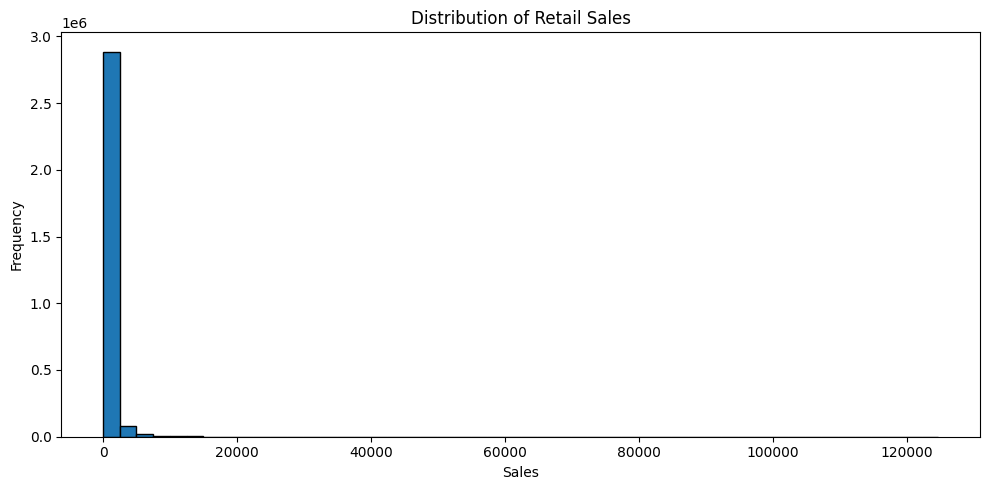

In [7]:
analyzer.plot_sales_distribution()

## 7. Sales Trends Over Time

We will aggregate sales across all stores and product families for each date. This will help us explore the overall daily sales trend and identify possible recurring patterns.

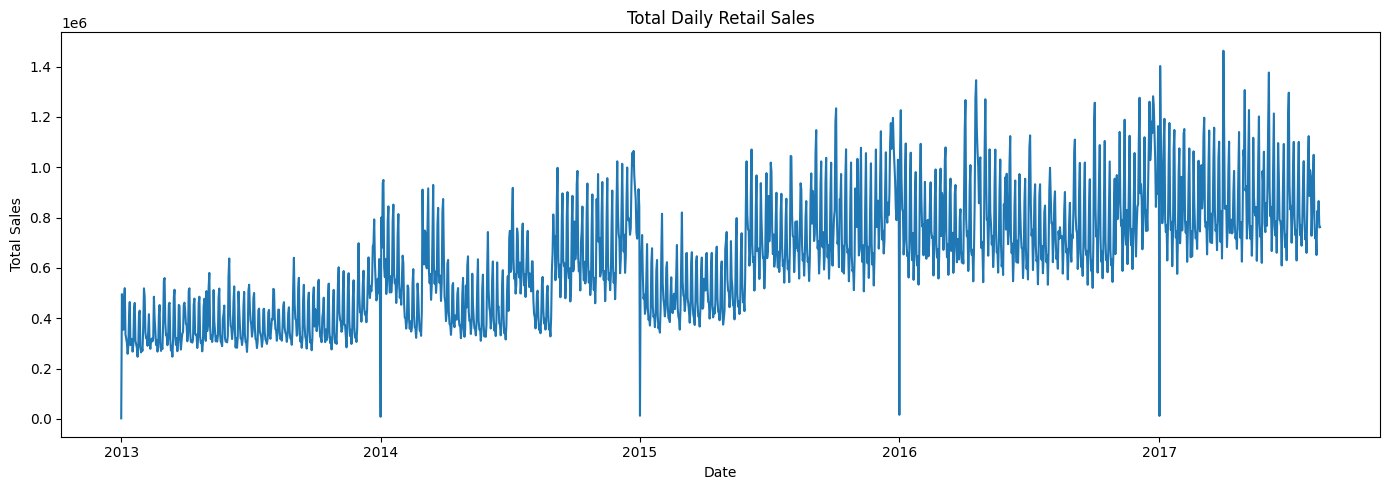

In [8]:
analyzer.plot_daily_sales()

In [9]:
analyzer.show_lowest_sales_dates()

Lowest 10 daily sales totals:
date
2013-01-01      2511.618999
2014-01-01      8602.065404
2017-01-01     12082.500997
2015-01-01     12773.616980
2016-01-01     16433.394000
2013-01-24    247245.690995
2013-03-14    247541.420096
2013-01-10    258982.003049
2013-01-29    264488.818076
2013-06-27    266525.458966
Name: sales, dtype: float64


## 8. Initial Findings

The initial exploration shows that the dataset contains daily sales observations across multiple stores and product families from January 2013 to August 2017.

Sales values vary considerably. The mean sales value is higher than the median, suggesting a right-skewed distribution.

When sales are aggregated across all stores and product families by date, the overall trend generally increases over the observed period, with frequent fluctuations.

The lowest daily sales totals occur on 1 January in each year shown in the dataset. This may be related to holiday effects or store operating schedules and requires further investigation.

These findings are preliminary. Additional analysis is needed to understand weekly patterns, holiday effects, and the most appropriate time series for forecasting.

## 9. Weekly Sales Patterns

In this section, we will compare average daily sales across the days of the week. This will help us investigate whether retail sales follow a recurring weekly pattern.

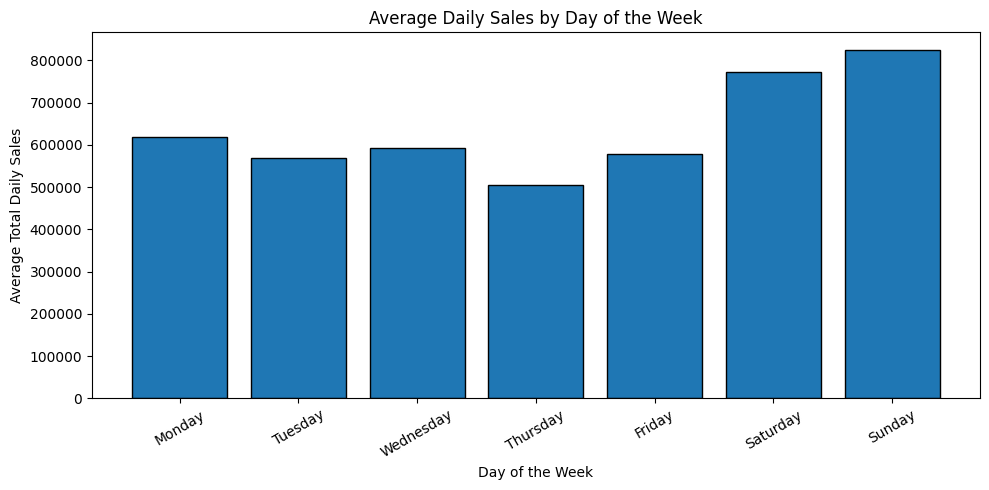

In [10]:
analyzer.plot_weekly_sales()

## 10. Sales by Store and Product Family

Sales may vary considerably between stores and product families. Comparing total sales across these groups will help us understand how sales are distributed throughout the business and inform our forecasting objective.

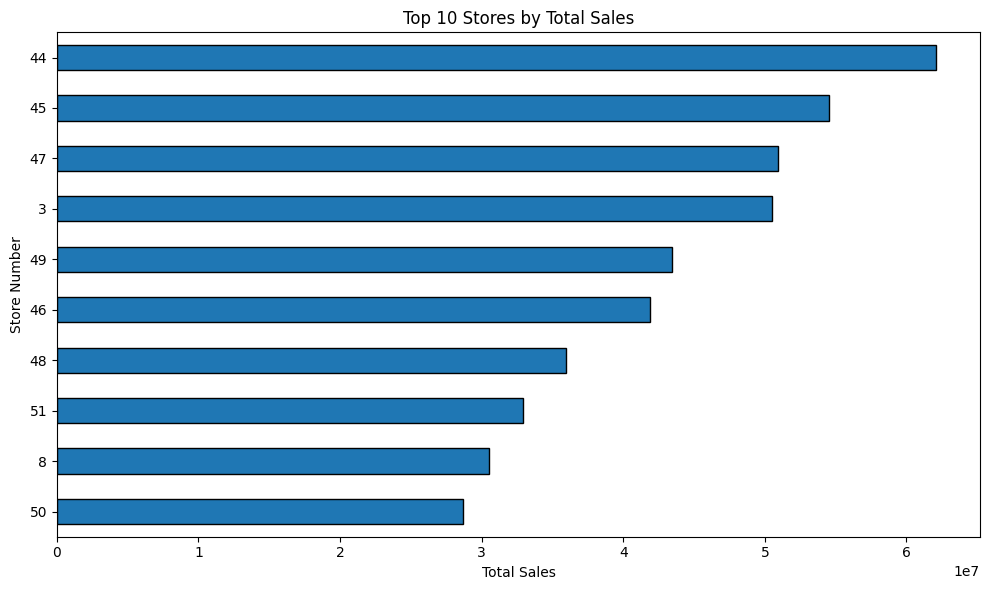

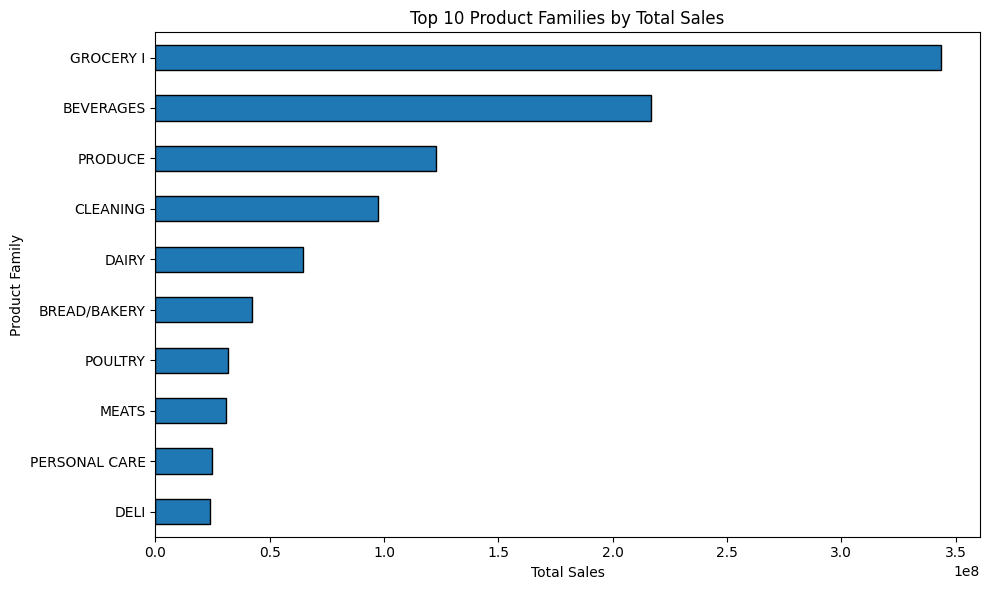

In [11]:
analyzer.plot_top_stores()
analyzer.plot_top_families()

## 11. Holiday Effects on Sales

Holidays and special events may influence retail sales. We will use the holiday and events dataset to identify dates marked as holidays or events and compare their total sales with sales on other dates.

This is an initial comparison and will not establish that holidays cause sales to change.

Average total daily sales:
is_holiday_date
Non-holiday dates      627547.659762
Holiday/event dates    694431.362793
Name: sales, dtype: float64


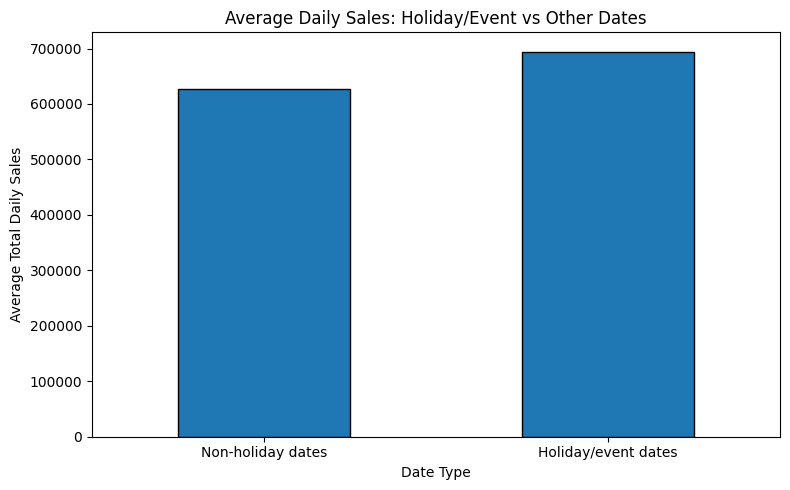

In [12]:
analyzer.compare_holiday_sales()

## 12. Exploratory Data Analysis: Key Findings

### Dataset overview
The training dataset contains 3,000,888 rows and six columns. It covers daily sales observations across 54 stores and 33 product families, from January 2013 to August 2017.

### Sales distribution
The mean sales value is higher than the median, and the histogram shows a concentration of observations at lower sales values. The distribution appears strongly right-skewed.

### Sales over time
Aggregated daily sales generally increase over the observed period, with frequent fluctuations and sharp drops around the beginning of each year. These drops require further investigation before any assumptions are made about their cause.

### Weekly patterns
Average total daily sales differ by weekday. Saturday and Sunday appear higher than the other days in the initial comparison.

### Store and product-family comparisons
Store 44 has the highest cumulative sales among the top ten stores shown. GROCERY I has the highest cumulative sales among product families, followed by BEVERAGES and PRODUCE.

### Holiday and event dates
Average total daily sales are approximately 694,431 on dates listed in the holidays/events dataset, compared with approximately 627,548 on other dates. This preliminary comparison does not establish causation.

### Next steps
The exploratory analysis provides an initial understanding of the data. The next phase will focus on data preprocessing, defining the forecasting series, checking chronological consistency, and preparing the data for time series modelling.